In [1]:
%pip install openpyxl pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

df = pd.read_csv("../book_management/book_sales.csv")

display(Markdown("# Book Sales Data Analysis"))
display(Markdown("## Dataset Preview"))

print(f"Number of records: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

display(df.head().style.set_caption("First Five Records"))


# Book Sales Data Analysis

## Dataset Preview

Number of records: 1,070
Number of columns: 15


,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,0,1975.000000,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.420000,155903,genre fiction,34160.000000,20496.000000,4.880000,1,HarperCollins Publishers,7000
1,1,1987.000000,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lewis, Dennis O'Neil",eng,Intermediate,4.230000,145267,genre fiction,12437.500000,7462.500000,1.990000,2,HarperCollins Publishers,6250
2,2,2015.000000,Go Set a Watchman,Harper Lee,eng,Novice,3.310000,138669,genre fiction,47795.000000,28677.000000,8.690000,3,"Amazon Digital Services, Inc.",5500
3,3,2008.000000,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.040000,150898,fiction,41250.000000,24750.000000,7.500000,3,Hachette Book Group,5500
4,4,2011.000000,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.040000,198283,genre fiction,37952.500000,22771.500000,7.990000,4,Penguin Group (USA) LLC,4750


In [7]:
df.columns = df.columns.str.strip()

print("Cleaned column names:")
print(df.columns.tolist())
df.columns = df.columns.str.strip()

Cleaned column names:
['index', 'Publishing Year', 'Book Name', 'Author', 'language_code', 'Author_Rating', 'Book_average_rating', 'Book_ratings_count', 'genre', 'gross sales', 'publisher revenue', 'sale price', 'sales rank', 'Publisher', 'units sold']


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Clean column names
df.columns = df.columns.str.strip()

# Professional chart styling
plt.rcParams.update({
    "figure.facecolor": "#FAF8F5",
    "axes.facecolor": "#FAF8F5",
    "axes.titlesize": 17,
    "axes.labelsize": 11,
    "font.size": 10,
    "font.family": "DejaVu Sans"
})

display(Markdown("# Book Sales Analytics Dashboard"))
display(Markdown(
    "Exploring book sales, publisher revenue, reader ratings "
    "and publishing trends."
))

print(f"Books analysed: {len(df):,}")
print(f"Unique titles: {df['Book Name'].nunique():,}")
print(f"Publishers: {df['Publisher'].nunique():,}")


# Book Sales Analytics Dashboard

Exploring book sales, publisher revenue, reader ratings and publishing trends.

Books analysed: 1,070
Unique titles: 1,045
Publishers: 9


In [9]:

metrics = pd.DataFrame({
    "Business Metric": [
        "Total Gross Sales",
        "Total Publisher Revenue",
        "Total Units Sold",
        "Average Book Rating",
        "Average Sale Price"
    ],
    "Value": [
        df["gross sales"].sum(),
        df["publisher revenue"].sum(),
        df["units sold"].sum(),
        df["Book_average_rating"].mean(),
        df["sale price"].mean()
    ]
})

display(
    metrics.style
    .hide(axis="index")
    .format({
        "Value": lambda x: f"{x:,.2f}"
    })
    .background_gradient(subset=["Value"], cmap="PuBuGn")
    .set_caption("Key Performance Indicators")
)


Business Metric,Value
Total Gross Sales,"1,986,586.55"
Total Publisher Revenue,"902,310.70"
Total Units Sold,"10,354,369.00"
Average Book Rating,4.01
Average Sale Price,4.87


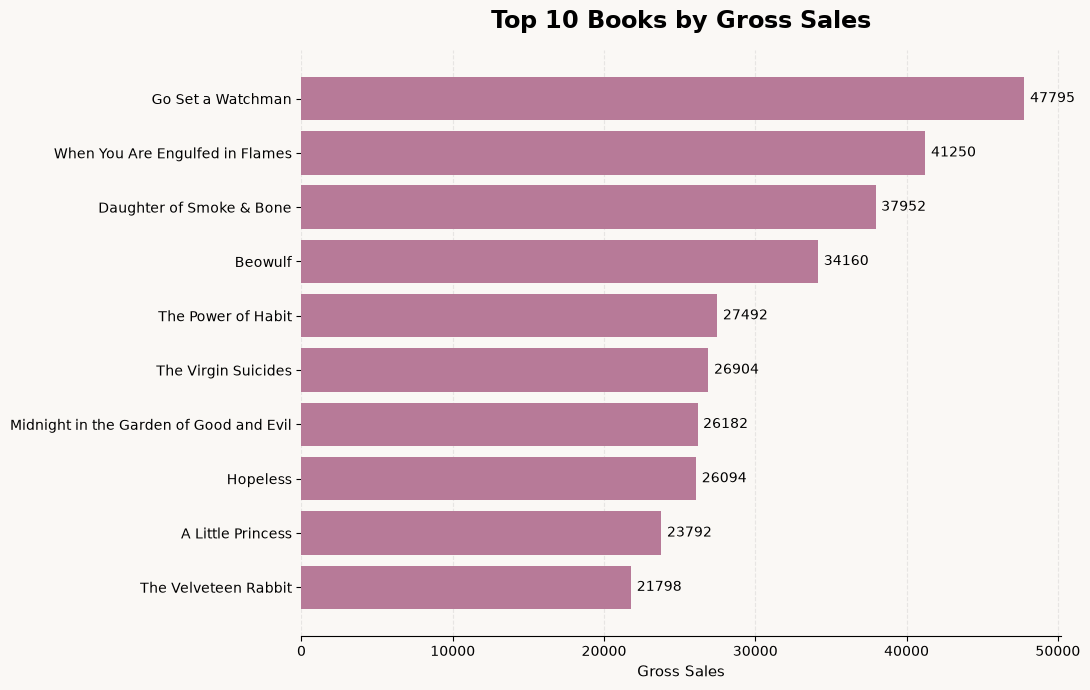

In [10]:

top_books = (
    df.groupby("Book Name", as_index=False)["gross sales"]
    .sum()
    .nlargest(10, "gross sales")
    .sort_values("gross sales")
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_books["Book Name"],
    top_books["gross sales"],
    color="#B77A98"
)

ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Top 10 Books by Gross Sales", pad=16, weight="bold")
ax.set_xlabel("Gross Sales")
ax.set_ylabel("")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


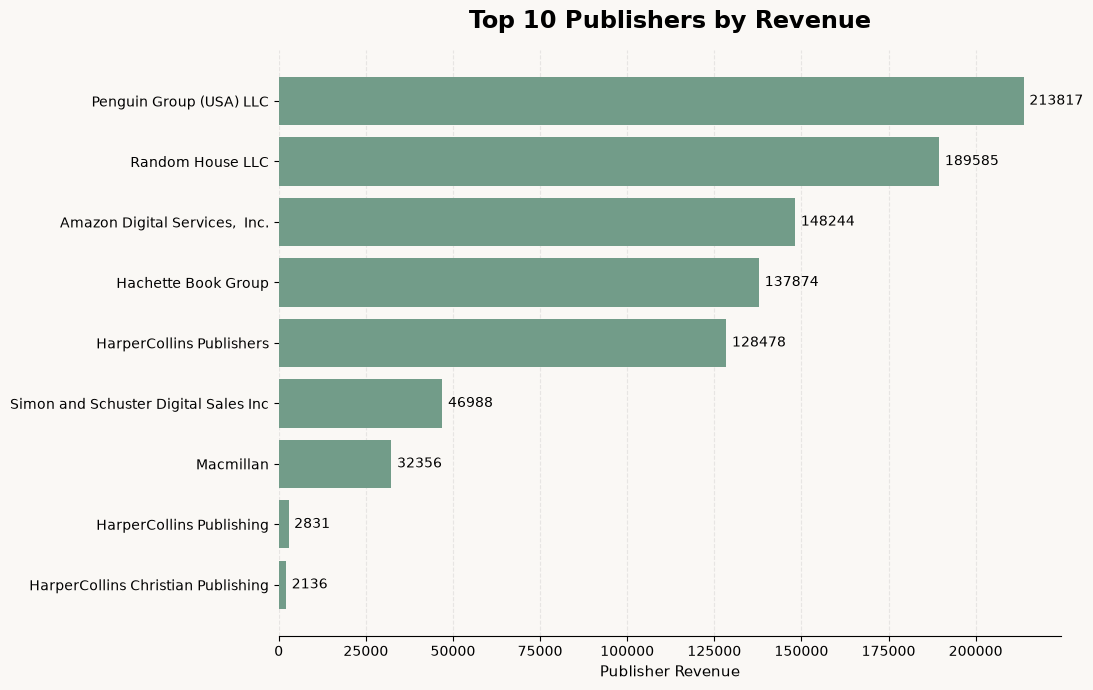

In [11]:

top_publishers = (
    df.groupby("Publisher", as_index=False)["publisher revenue"]
    .sum()
    .nlargest(10, "publisher revenue")
    .sort_values("publisher revenue")
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_publishers["Publisher"],
    top_publishers["publisher revenue"],
    color="#729C89"
)

ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Top 10 Publishers by Revenue", pad=16, weight="bold")
ax.set_xlabel("Publisher Revenue")
ax.set_ylabel("")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


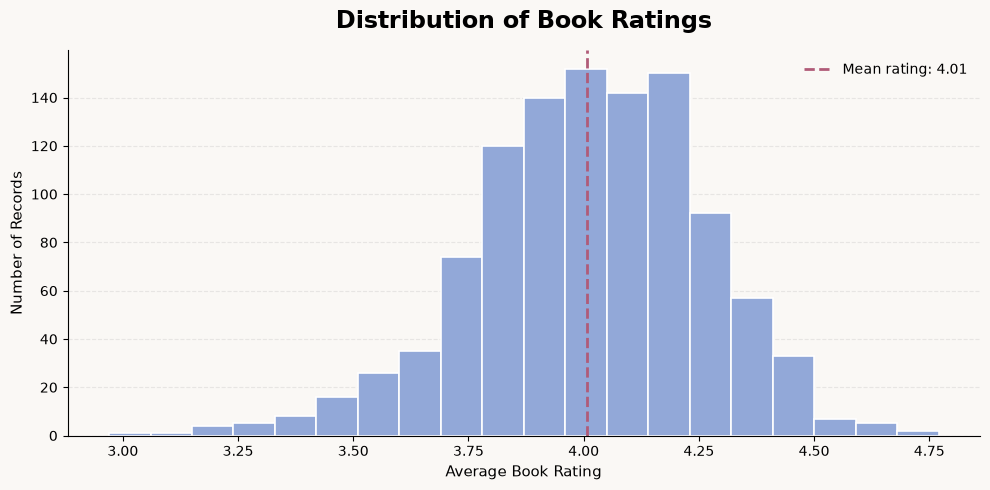

In [12]:

ratings = df["Book_average_rating"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    ratings,
    bins=20,
    color="#92A8D8",
    edgecolor="white",
    linewidth=1.2
)

ax.axvline(
    ratings.mean(),
    color="#B05B78",
    linestyle="--",
    linewidth=2,
    label=f"Mean rating: {ratings.mean():.2f}"
)

ax.set_title("Distribution of Book Ratings", pad=16, weight="bold")
ax.set_xlabel("Average Book Rating")
ax.set_ylabel("Number of Records")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


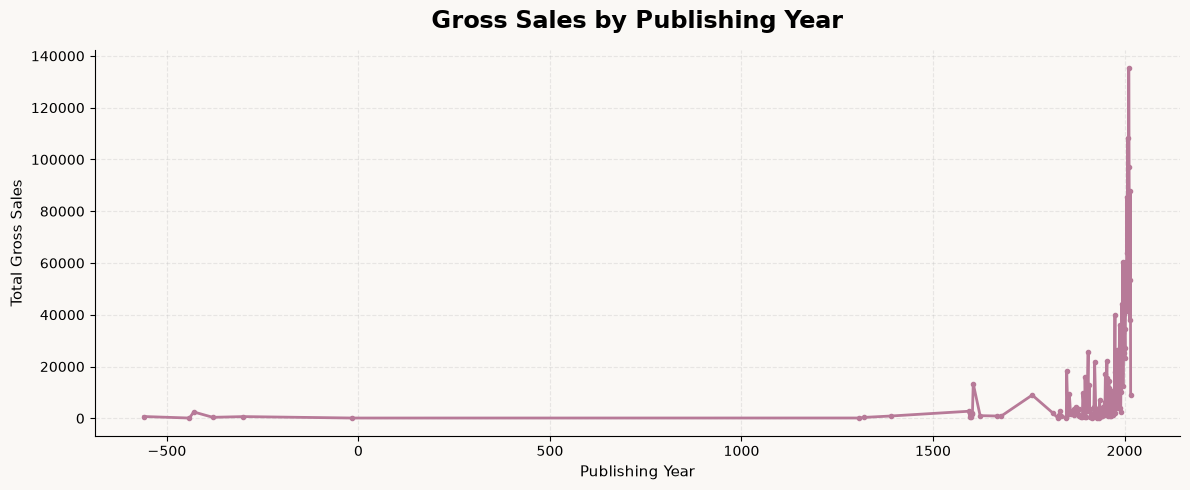

In [13]:

yearly_sales = (
    df.dropna(subset=["Publishing Year"])
    .groupby("Publishing Year")["gross sales"]
    .sum()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    yearly_sales.index,
    yearly_sales.values,
    color="#B77A98",
    linewidth=2,
    marker="o",
    markersize=3
)

ax.set_title("Gross Sales by Publishing Year", pad=16, weight="bold")
ax.set_xlabel("Publishing Year")
ax.set_ylabel("Total Gross Sales")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()


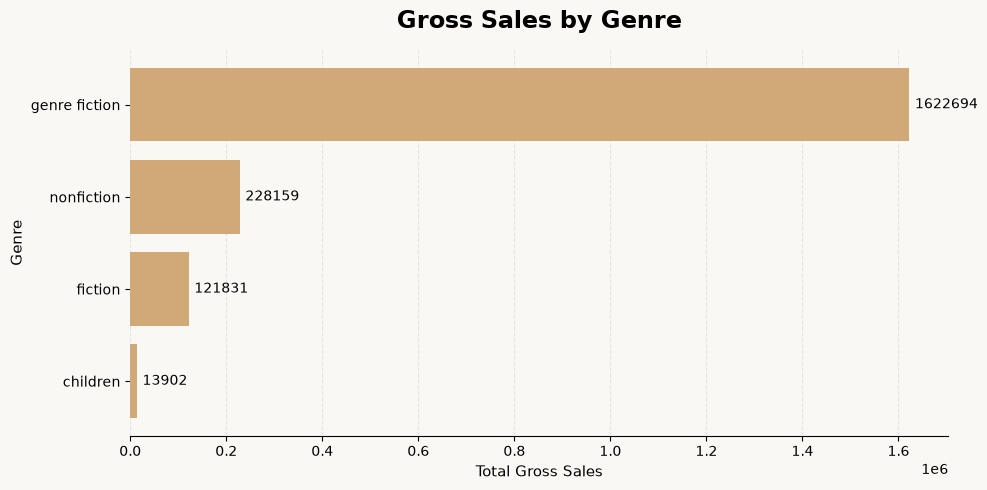

In [14]:

genre_sales = (
    df.groupby("genre")["gross sales"]
    .sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    genre_sales.index.astype(str),
    genre_sales.values,
    color="#D1A878"
)

ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Gross Sales by Genre", pad=16, weight="bold")
ax.set_xlabel("Total Gross Sales")
ax.set_ylabel("Genre")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


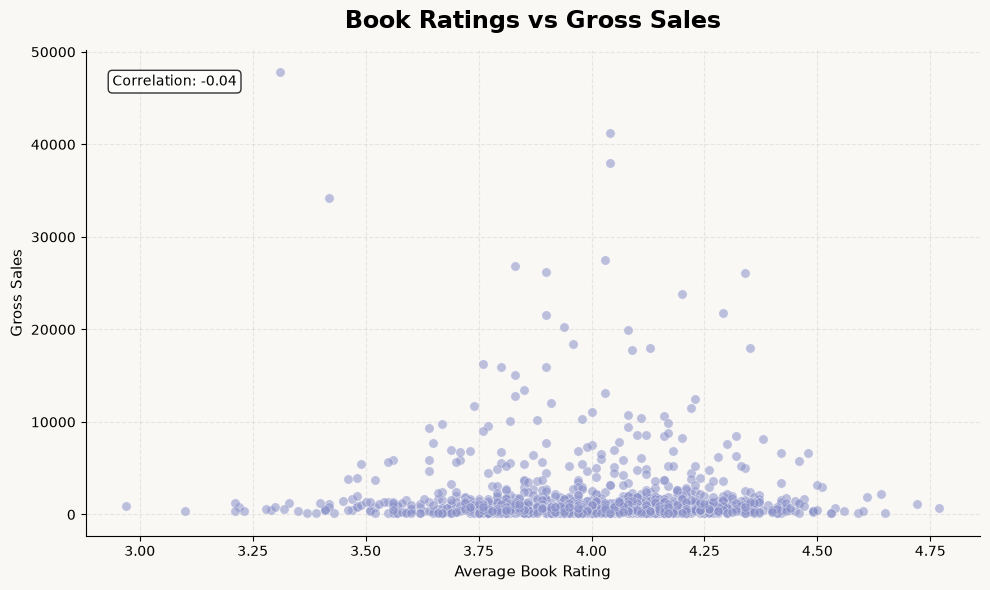

In [15]:

plot_data = df.dropna(
    subset=["Book_average_rating", "gross sales"]
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    plot_data["Book_average_rating"],
    plot_data["gross sales"],
    alpha=0.55,
    s=45,
    color="#8A91C9",
    edgecolors="white",
    linewidths=0.4
)

ax.set_title("Book Ratings vs Gross Sales", pad=16, weight="bold")
ax.set_xlabel("Average Book Rating")
ax.set_ylabel("Gross Sales")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(linestyle="--", alpha=0.25)

correlation = plot_data["Book_average_rating"].corr(
    plot_data["gross sales"]
)

ax.text(
    0.03, 0.95,
    f"Correlation: {correlation:.2f}",
    transform=ax.transAxes,
    va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.8}
)

plt.tight_layout()
plt.show()


In [17]:


import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

# Calculate key findings
top_book = df.loc[df["gross sales"].idxmax()]

top_publisher = (
    df.groupby("Publisher")["publisher revenue"]
    .sum()
    .idxmax()
)

top_genre = (
    df.groupby("genre")["gross sales"]
    .sum()
    .idxmax()
)

total_books = len(df)
total_sales = df["gross sales"].sum()
total_revenue = df["publisher revenue"].sum()
total_units = df["units sold"].sum()
average_rating = df["Book_average_rating"].mean()

# Dashboard heading
display(HTML("""
<div style="
    background: linear-gradient(135deg, #493548, #91677E);
    padding: 28px;
    border-radius: 16px;
    color: white;
    font-family: Arial;
    margin-bottom: 18px;">
    <h1 style="margin: 0; color: white;">Book Sales Insights</h1>
    <p style="margin: 8px 0 0; color: #F5EAF0;">
        A summary of sales performance, revenue and reader ratings
    </p>
</div>
"""))

# KPI cards
cards = [
    ("BOOKS ANALYSED", f"{total_books:,}", "#E9D8E2"),
    ("GROSS SALES", f"{total_sales:,.2f}", "#DDE9F5"),
    ("PUBLISHER REVENUE", f"{total_revenue:,.2f}", "#DCEDE3"),
    ("UNITS SOLD", f"{total_units:,.0f}", "#F5E8D2"),
    ("AVERAGE RATING", f"{average_rating:.2f} / 5", "#E8E2F5")
]

card_html = """
<div style="display: flex; flex-wrap: wrap; gap: 12px;
            font-family: Arial; margin-bottom: 22px;">
"""

for label, value, colour in cards:
    card_html += f"""
    <div style="flex: 1; min-width: 145px; background: {colour};
                padding: 18px; border-radius: 12px;">
        <div style="font-size: 11px; letter-spacing: 1px;
                    color: #574A55; font-weight: bold;">
            {label}
        </div>
        <div style="font-size: 23px; font-weight: bold;
                    color: #493548; margin-top: 10px;">
            {value}
        </div>
    </div>
    """

card_html += "</div>"
display(HTML(card_html))

# Highlighted findings
display(HTML("""
<h2 style="color: #493548; font-family: Arial;">
    ✦ Standout Findings
</h2>
"""))

insights = [
    ("Highest-grossing book record", top_book["Book Name"],
     f"Gross sales: {top_book['gross sales']:,.2f}"),
    ("Leading publisher by combined revenue", top_publisher,
     f"Revenue: {df.groupby('Publisher')['publisher revenue'].sum().max():,.2f}"),
    ("Top genre by gross sales", top_genre,
     f"Gross sales: {df.groupby('genre')['gross sales'].sum().max():,.2f}")
]

for heading, name, detail in insights:
    display(HTML(f"""
    <div style="border-left: 5px solid #B77A98;
                background: #FAF6F8; padding: 14px 18px;
                margin: 10px 0; border-radius: 5px;
                font-family: Arial;">
        <div style="font-size: 12px; color: #786575;
                    text-transform: uppercase; letter-spacing: 1px;">
            {heading}
        </div>
        <div style="font-size: 19px; font-weight: bold;
                    color: #493548; margin: 6px 0;">
            {name}
        </div>
        <div style="font-size: 14px; color: #574A55;">
            {detail}
        </div>
    </div>
    """))

display(HTML("""
<p style="color: #786575; font-family: Arial; font-size: 12px;
          margin-top: 20px;">
    Book Sales Analytics · Python, Pandas & Matplotlib
</p>
"""))



In [ ]:
import numpy as np

array_1d = np.arange(12)
print("1D Array:")
print(array_1d)
print("Shape:", array_1d.shape)

array_2d = np.arange(12).reshape(3, 4)
print("\n2D Array:")
print(array_2d)
print("Shape:", array_2d.shape)

array_3d = np.arange(40).reshape(2, 5, 4)
print("\n3D Array:")
print(array_3d)
print("Shape:", array_3d.shape)